<a href="https://colab.research.google.com/github/vikramsingh456/ai-ml/blob/dev/ElbowSilhouetteDBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install kneed

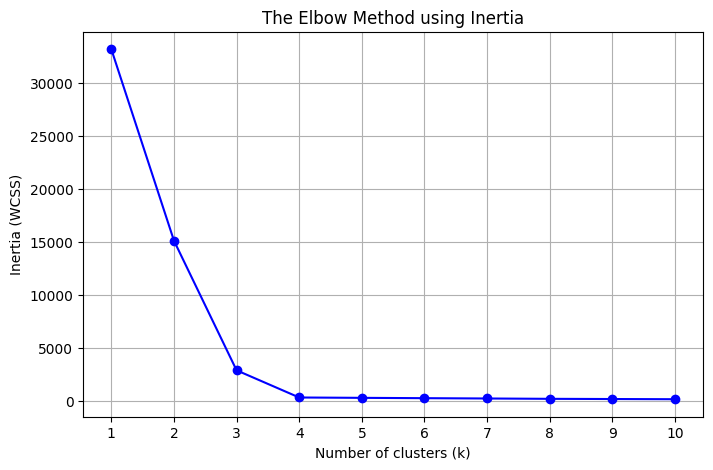

The optimal number of clusters is: 3
----- Setting Optimal K=4 by using the plot -------
Number of points per cluster:
Cluster
0    125
1    125
2    125
3    125
Name: count, dtype: int64
----------------------------------------
Cluster 0:
  - Point Count: 125
  - X1 Range: [2.70, 6.49]
  - X2 Range: [0.59, 3.23]
Cluster 1:
  - Point Count: 125
  - X1 Range: [-9.79, -7.30]
  - X2 Range: [5.87, 8.80]
Cluster 2:
  - Point Count: 125
  - X1 Range: [-8.50, -5.34]
  - X2 Range: [-8.21, -5.30]
Cluster 3:
  - Point Count: 125
  - X1 Range: [-4.08, -1.12]
  - X2 Range: [7.82, 11.33]


In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from kneed import KneeLocator

import numpy as np
import pandas as pd

# 1. Generate synthetic data with 4 distinct clusters
X, y = make_blobs(n_samples=500, centers=4, cluster_std=0.60, random_state=42)

# 2. Calculate inertia for k values ranging from 1 to 10
inertia_values = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X)
    inertia_values.append(kmeans.inertia_)

# 3. Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_range, inertia_values, marker='o', linestyle='-', color='b')
plt.title('The Elbow Method using Inertia')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (WCSS)')
plt.xticks(k_range)
plt.grid(True)
plt.show()


#Programming way to get K value

k1 = KneeLocator(k_range, inertia_values, curve='convex', direction='decreasing', S=3.0)
optimal_k = k1.elbow
print("The optimal number of clusters is:",optimal_k)

#Info of each cluster
# Kneelocator is giving me optimal k =3 but on plot it is 4 so using optimal k =4
print("----- Setting Optimal K=4 by using the plot -------")
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X)

df = pd.DataFrame(X, columns=['X1', 'X2'])
df['Cluster'] = cluster_labels
df.head()

counts = df['Cluster'].value_counts().sort_index()
print("Number of points per cluster:")
print(counts)
print("-" * 40)

# 5. Find the range (min and max boundaries) for each cluster
for cluster_id in range(optimal_k):
  cluster_points = df[df['Cluster'] == cluster_id]

  x1_min, x1_max = cluster_points['X1'].min(), cluster_points['X1'].max()
  x2_min, x2_max = cluster_points['X2'].min(), cluster_points['X2'].max()

  print(f"Cluster {cluster_id}:")
  print(f"  - Point Count: {len(cluster_points)}")
  print(f"  - X1 Range: [{x1_min:.2f}, {x1_max:.2f}]")
  print(f"  - X2 Range: [{x2_min:.2f}, {x2_max:.2f}]")






In [8]:
#Silhouette Method
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score


import numpy as np
import pandas as pd

# 1. Generate synthetic data with 4 distinct clusters
X, y = make_blobs(n_samples=500, centers=4, cluster_std=0.60, random_state=42)

silhouette_scores = []
k_range = range(2, 11)
for k in k_range:
  kmeans  = KMeans(n_clusters=k, n_init=10, random_state=42)
  cluster_labels = kmeans.fit_predict(X)
  score = silhouette_score(X, cluster_labels)
  silhouette_scores.append(score)

optimal_k = range(2, 11)[np.argmax(silhouette_scores)]
print("Optimal k via Silhouette:", optimal_k)


Optimal k via Silhouette: 4


Estimated number of clusters: 2
Estimated number of noise points: 0


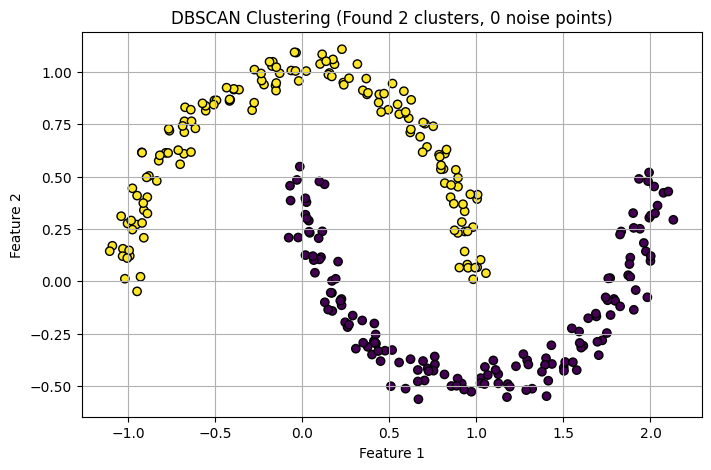

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

# 1. Generate non-linear synthetic data (two interleaving crescents)
X, y = make_moons(n_samples=300, noise=0.05, random_state=42)

# 2. Initialize and fit DBSCAN
# eps: neighborhood distance, min_samples: density threshold
dbscan = DBSCAN(eps=
                .2, min_samples=5)
cluster_labels = dbscan.fit_predict(X)

# 3. Analyze results
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = list(cluster_labels).count(-1)

print(f"Estimated number of clusters: {n_clusters}")
print(f"Estimated number of noise points: {n_noise}")

# 4. Plot the clusters (Noise points are labeled as -1)
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=cluster_labels, cmap='viridis', edgecolor='k')
plt.title(f'DBSCAN Clustering (Found {n_clusters} clusters, {n_noise} noise points)')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()